# 04 · Segmentación de clientes con K-Means

**Pregunta de negocio:** ¿existen diferentes tipos de clientes? ¿Quiénes son los clientes VIP, quiénes los habituales y quiénes los que hemos perdido o estamos a punto de perder?

Tratar a todos los clientes igual es caro e ineficaz: enviar un descuento a un cliente VIP que iba a comprar igualmente es perder margen, y no hacer nada con un buen cliente que se está enfriando es perder ingresos. La **segmentación** agrupa a los clientes con comportamientos parecidos para poder diseñar **una estrategia distinta para cada grupo**.

**Enfoque:**
1. Seleccionar y preparar las variables (RFM con logaritmo + estandarización).
2. Elegir el número de grupos (*k*) con cuatro métricas complementarias.
3. Comprobar que la segmentación es **estable** y compararla con un conjunto de variables más amplio.
4. **Interpretar** cada grupo, ponerle nombre y cuantificar su peso en el negocio.
5. Traducir los segmentos en **acciones y prioridades** concretas.

**¿Por qué K-Means?** Es el algoritmo de clustering más usado en segmentación de clientes porque es rápido, escala bien y, sobre todo, produce **centroides interpretables**: cada grupo queda resumido por un "cliente tipo" fácil de explicar al equipo de negocio.

### 0. Librerías

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

# Estilo común de los gráficos: ejes y rejilla discretos para que destaquen los datos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "font.size": 10,
})
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS = "#b5b4ad"

SEMILLA = 42  # fijamos la semilla para que los resultados sean reproducibles

### 1. Carga de las features
Partimos de la tabla de clientes construida en `03_construccion_features`.

In [2]:
RUTA_FEATURES = Path("../data/processed/features_clientes.csv")
RUTA_SEGMENTOS = Path("../data/processed/segmentos_clientes.csv")
DIR_MODELOS = Path("../models")
DIR_MODELOS.mkdir(exist_ok=True)

features = pd.read_csv(RUTA_FEATURES, index_col="customer_id")
print(f"{len(features):,} clientes · {features.shape[1]} variables")
features.head()

5,832 clientes · 15 variables


,pais,es_reino_unido,recencia,frecuencia,gasto,ticket_medio,productos_distintos,unidades,antiguedad_dias,vida_cliente_dias,frecuencia_mensual,dias_entre_compras,gasto_bruto,gasto_cancelado,tasa_cancelacion
customer_id,,,,,,,,,,,,,,,
12346,United Kingdom,1,326,3,169.36,56.453333,25,74239,648,322,0.140926,161.000000,77352.96,77183.60,0.997811
12347,Iceland,0,3,8,4921.53,615.191250,126,2967,405,402,0.601284,57.428571,4921.53,0.00,0.000000
12348,Finland,0,76,5,1658.40,331.680000,24,2704,439,363,0.346697,90.750000,1658.40,0.00,0.000000
12349,Italy,0,19,3,3654.54,1218.180000,137,1621,590,571,0.154780,285.500000,3678.69,24.15,0.006565
12350,Norway,0,311,1,294.40,294.400000,16,196,311,0,0.097878,NaN,294.40,0.00,0.000000


### 2. Preparación de los datos

#### 2.1 Selección de variables
Usamos las tres variables **RFM** (recencia, frecuencia y gasto). Como vimos en el notebook anterior:
- Resumen las tres dimensiones clave del valor de un cliente: **¿está activo?, ¿es fiel?, ¿cuánto vale?**
- Evitan acumular variables de volumen que repiten la misma información (unidades y productos distintos tienen correlaciones de 0,76-0,94 con frecuencia y gasto).
- Son fáciles de explicar al negocio, lo que hace que los segmentos sean accionables.

Más adelante comprobaremos si añadir variables mejora la segmentación.

#### 2.2 Transformación y escalado
K-Means agrupa a los clientes según la **distancia euclídea**, lo que implica dos problemas que debemos corregir:

1. **Asimetría:** frecuencia y gasto tienen colas muy largas. Sin transformar, unos pocos clientes enormes dominarían las distancias. Aplicamos `log(1 + x)`.
2. **Escala:** el gasto va de 0 a cientos de miles y la frecuencia de 1 a unos cientos. Sin escalar, el gasto decidiría casi solo la segmentación. Aplicamos `StandardScaler` (media 0 y desviación típica 1) para que **las tres variables pesen lo mismo**.

Encapsulamos ambos pasos en un `Pipeline` de scikit-learn. Así, el mismo preprocesado se aplica exactamente igual cuando queramos asignar segmento a clientes nuevos.

In [3]:
VARIABLES = ["recencia", "frecuencia", "gasto"]

preprocesado = make_pipeline(
    FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
    StandardScaler(),
)

X = preprocesado.fit_transform(features[VARIABLES])

pd.DataFrame(X, columns=VARIABLES).describe().round(2)

,recencia,frecuencia,gasto
count,5832.00,5832.00,5832.00
mean,-0.00,0.00,0.00
std,1.00,1.00,1.00
min,-2.47,-1.06,-3.95
25%,-0.76,-1.06,-0.71
50%,0.07,-0.20,-0.04
75%,0.96,0.66,0.65
max,1.40,5.42,4.71


Las tres variables tienen ahora media 0 y desviación 1: ya son comparables entre sí.

### 3. ¿Cuántos segmentos? Elección de *k*
K-Means necesita que le digamos el número de grupos. No hay una respuesta única, así que combinamos **cuatro métricas** y el **criterio de negocio**:

| Métrica | Qué mide | Mejor si... |
|---|---|---|
| **Inercia (método del codo)** | Distancia de cada cliente a su centroide | Buscamos el "codo": el punto a partir del cual añadir grupos mejora poco |
| **Silhouette** | Cuánto se parece un cliente a su grupo frente al grupo vecino (-1 a 1) | Más alto |
| **Davies-Bouldin** | Parecido medio entre cada grupo y su grupo más similar | Más bajo |
| **Calinski-Harabasz** | Ratio entre dispersión entre grupos y dentro de los grupos | Más alto |

In [4]:
rango_k = range(2, 11)
metricas = []

for k in rango_k:
    modelo = KMeans(n_clusters=k, random_state=SEMILLA, n_init=20)
    etiquetas_k = modelo.fit_predict(X)
    metricas.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(X, etiquetas_k),
        "davies_bouldin": davies_bouldin_score(X, etiquetas_k),
        "calinski_harabasz": calinski_harabasz_score(X, etiquetas_k),
        "tamaño_grupo_menor": np.bincount(etiquetas_k).min() / len(etiquetas_k),
    })

metricas = pd.DataFrame(metricas).set_index("k")
metricas.round(3)

,inercia,silhouette,davies_bouldin,calinski_harabasz,tamaño_grupo_menor
k,,,,,
2,8520.826,0.438,0.873,6140.868,0.398
3,6293.948,0.347,1.036,5187.325,0.212
4,4861.854,0.367,0.930,5048.291,0.204
5,4041.450,0.345,0.944,4849.754,0.077
6,3516.220,0.333,0.962,4632.801,0.079
7,3153.109,0.305,0.985,4416.227,0.056
8,2870.120,0.294,1.005,4239.809,0.063
9,2626.424,0.288,1.020,4120.915,0.045
10,2435.665,0.289,1.021,3999.893,0.039


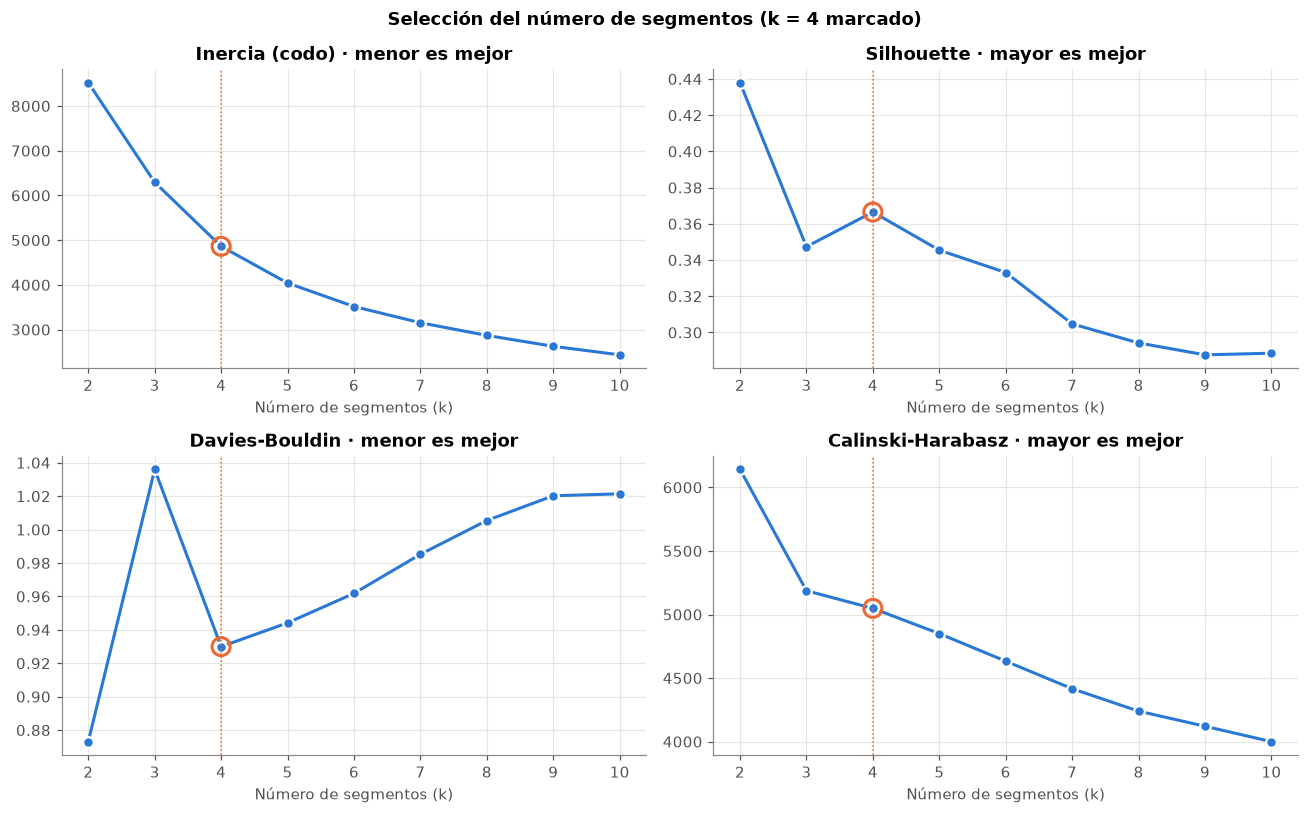

In [5]:
K_ELEGIDO = 4

paneles = [
    ("inercia", "Inercia (codo) · menor es mejor"),
    ("silhouette", "Silhouette · mayor es mejor"),
    ("davies_bouldin", "Davies-Bouldin · menor es mejor"),
    ("calinski_harabasz", "Calinski-Harabasz · mayor es mejor"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (columna, titulo) in zip(axes.flat, paneles):
    ax.plot(metricas.index, metricas[columna], color=AZUL, marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=1.5)
    ax.scatter(K_ELEGIDO, metricas.loc[K_ELEGIDO, columna], s=140, facecolor="none",
               edgecolor=NARANJA, linewidth=2, zorder=3)
    ax.axvline(K_ELEGIDO, color=NARANJA, linewidth=1, linestyle=":")
    ax.set_title(titulo)
    ax.set_xticks(list(rango_k))
    ax.set_xlabel("Número de segmentos (k)")
fig.suptitle(f"Selección del número de segmentos (k = {K_ELEGIDO} marcado)", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación:**
- **Silhouette** es máximo con k = 2, pero dos grupos ("buenos" y "malos" clientes) es una división demasiado simple para diseñar estrategias. Después de k = 2, **k = 4 es el siguiente mejor valor** (un máximo local) y a partir de ahí desciende.
- **Davies-Bouldin** tiene un **mínimo local en k = 4**: es el punto en que los grupos están mejor separados entre sí de todo el rango de 3 a 10.
- **El codo** de la inercia se sitúa en torno a k = 4: a partir de ahí cada grupo adicional reduce la inercia cada vez menos.
- **Calinski-Harabasz** decrece con k (habitual en este tipo de datos) y no señala un punto claro.

Además, con k = 4 todos los grupos tienen un **tamaño relevante** (el más pequeño tiene ~20 % de los clientes), lo que los hace útiles para campañas. En cambio, con k = 5 aparece un grupo con menos del 8 % de los clientes: demasiado pequeño para justificar una estrategia propia.

**Decisión: k = 4.** Es el mejor equilibrio entre calidad estadística e interpretabilidad. Además coincide con la intuición del esquema del proyecto (VIP, regulares, inactivos...), pero esta vez el número sale de los datos.

> Un silhouette en torno a 0,35-0,45 indica una estructura **moderada**: los clientes no forman islas separadas sino un continuo (como vimos en el notebook 03). Es lo habitual en segmentación de clientes reales, y por eso es tan importante validar que la segmentación es estable y tiene sentido de negocio.

### 4. Modelo final
Entrenamos K-Means con k = 4. Usamos `n_init=20`: el algoritmo se ejecuta 20 veces con centroides iniciales distintos y se queda con la mejor solución, lo que evita quedarse en un mal mínimo local.

In [6]:
kmeans = KMeans(n_clusters=K_ELEGIDO, random_state=SEMILLA, n_init=20)
features["cluster"] = kmeans.fit_predict(X)

features["cluster"].value_counts().sort_index()

cluster
0    1440
1    1189
2    1253
3    1950
Name: count, dtype: int64

### 5. ¿Es estable la segmentación?
Una segmentación solo es útil si no cambia por casualidad. Lo comprobamos de dos formas usando el **Adjusted Rand Index (ARI)**, que mide cuánto coinciden dos agrupaciones (1 = idénticas, 0 = coincidencia aleatoria):

1. **Distintas semillas:** entrenamos el modelo con 10 semillas aleatorias diferentes.
2. **Submuestras:** entrenamos con un 80 % aleatorio de los clientes y asignamos a todos los clientes, para ver si los grupos se mantienen aunque cambien los datos.

In [7]:
ari_semillas = []
for semilla in range(10):
    etiquetas_alt = KMeans(n_clusters=K_ELEGIDO, random_state=semilla, n_init=20).fit_predict(X)
    ari_semillas.append(adjusted_rand_score(features["cluster"], etiquetas_alt))

rng = np.random.default_rng(SEMILLA)
ari_submuestras = []
for _ in range(10):
    indices = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    modelo_sub = KMeans(n_clusters=K_ELEGIDO, random_state=SEMILLA, n_init=20).fit(X[indices])
    ari_submuestras.append(adjusted_rand_score(features["cluster"], modelo_sub.predict(X)))

print(f"ARI con distintas semillas: media {np.mean(ari_semillas):.3f} · mínimo {np.min(ari_semillas):.3f}")
print(f"ARI con submuestras del 80 %: media {np.mean(ari_submuestras):.3f} · mínimo {np.min(ari_submuestras):.3f}")

ARI con distintas semillas: media 1.000 · mínimo 0.999
ARI con submuestras del 80 %: media 0.981 · mínimo 0.949


Los valores de ARI son muy cercanos a 1: **la segmentación es muy estable**. Los grupos no dependen de la semilla ni de qué clientes concretos usemos para entrenar, sino de la estructura real de los datos.

### 6. ¿Mejora la segmentación con más variables?
En el notebook 03 nos planteamos si añadir `productos_distintos` y `ticket_medio` (con logaritmo) mejoraría los grupos. Lo comprobamos con las mismas métricas para k = 4:

In [8]:
conjuntos = {
    "RFM": ["recencia", "frecuencia", "gasto"],
    "RFM + productos distintos": ["recencia", "frecuencia", "gasto", "productos_distintos"],
    "RFM + ticket medio": ["recencia", "frecuencia", "gasto", "ticket_medio"],
    "RFM + productos + ticket": ["recencia", "frecuencia", "gasto", "productos_distintos", "ticket_medio"],
}

comparativa = []
for nombre, columnas in conjuntos.items():
    X_alt = make_pipeline(FunctionTransformer(np.log1p), StandardScaler()).fit_transform(features[columnas])
    etiquetas_alt = KMeans(n_clusters=K_ELEGIDO, random_state=SEMILLA, n_init=20).fit_predict(X_alt)
    comparativa.append({
        "variables": nombre,
        "silhouette": silhouette_score(X_alt, etiquetas_alt),
        "davies_bouldin": davies_bouldin_score(X_alt, etiquetas_alt),
        "ARI vs RFM": adjusted_rand_score(features["cluster"], etiquetas_alt),
    })

pd.DataFrame(comparativa).set_index("variables").round(3)

,silhouette,davies_bouldin,ARI vs RFM
variables,,,
RFM,0.367,0.930,1.000
RFM + productos distintos,0.309,1.102,0.661
RFM + ticket medio,0.280,1.148,0.421
RFM + productos + ticket,0.243,1.298,0.384


Añadir variables **empeora todas las métricas**: el silhouette baja de 0,37 a 0,24-0,31 y Davies-Bouldin sube de 0,93 a 1,10-1,30, es decir, los grupos quedan **más solapados**. Además, el ARI muestra que los grupos cambian bastante: el algoritmo empieza a separar a los clientes por el **tamaño de sus pedidos** (ticket medio) en lugar de por su **actividad y valor**, que es lo que necesitamos para decidir acciones de retención.

**Decisión: nos quedamos con RFM**, aplicando el principio de parsimonia (el modelo más simple que funciona igual de bien). Las demás variables no se pierden: las usaremos para **describir** los segmentos.

### 7. Interpretación de los segmentos
Ahora la parte más importante: entender **quién hay en cada grupo**. Calculamos el perfil de cada cluster con la **mediana** (más representativa que la media en variables tan sesgadas).

In [9]:
perfil = features.groupby("cluster").agg(
    clientes=("recencia", "size"),
    recencia_mediana=("recencia", "median"),
    frecuencia_mediana=("frecuencia", "median"),
    gasto_mediano=("gasto", "median"),
    ticket_medio_mediano=("ticket_medio", "median"),
    productos_distintos_mediana=("productos_distintos", "median"),
    antiguedad_mediana=("antiguedad_dias", "median"),
    ingresos_totales=("gasto", "sum"),
)
perfil["% clientes"] = perfil["clientes"] / perfil["clientes"].sum() * 100
perfil["% ingresos"] = perfil["ingresos_totales"] / perfil["ingresos_totales"].sum() * 100
perfil.round(1)

,clientes,recencia_mediana,frecuencia_mediana,gasto_mediano,ticket_medio_mediano,productos_distintos_mediana,antiguedad_mediana,ingresos_totales,% clientes,% ingresos
cluster,,,,,,,,,,
0,1440,184.5,4.5,1432.4,311.2,64.0,619.0,2678152.0,24.7,16.4
1,1189,17.0,13.0,4808.9,360.1,165.0,678.0,12049086.4,20.4,73.6
2,1253,24.0,3.0,705.1,246.9,43.0,219.0,1025356.2,21.5,6.3
3,1950,402.0,1.0,266.5,196.9,17.5,443.5,608953.7,33.4,3.7


#### 7.1 Asignar nombre a cada segmento
Los números de cluster (0, 1, 2, 3) son arbitrarios: podrían cambiar si se reentrena el modelo. Por eso asignamos los nombres **con reglas basadas en el perfil**, no a mano:

- **VIP**: el grupo con mayor gasto mediano.
- **Inactivos**: de los restantes, el que lleva más tiempo sin comprar.
- De los dos que quedan, el más reciente son los **Prometedores** (compraron hace poco, pero todavía poco) y el otro, **En riesgo** (han sido buenos clientes, pero hace meses que no compran).

In [10]:
restantes = perfil.sort_values("gasto_mediano", ascending=False).index.tolist()
vip = restantes.pop(0)
inactivos = perfil.loc[restantes, "recencia_mediana"].idxmax()
restantes.remove(inactivos)
prometedores = perfil.loc[restantes, "recencia_mediana"].idxmin()
restantes.remove(prometedores)
en_riesgo = restantes[0]

NOMBRES = {vip: "VIP", prometedores: "Prometedores", en_riesgo: "En riesgo", inactivos: "Inactivos"}
ORDEN_SEGMENTOS = ["VIP", "Prometedores", "En riesgo", "Inactivos"]
COLORES = {"VIP": AZUL, "Prometedores": AQUA, "En riesgo": NARANJA, "Inactivos": AMARILLO}

features["segmento"] = pd.Categorical(features["cluster"].map(NOMBRES), categories=ORDEN_SEGMENTOS, ordered=True)
perfil.index = perfil.index.map(NOMBRES)
perfil = perfil.loc[ORDEN_SEGMENTOS]

perfil[["clientes", "% clientes", "% ingresos", "recencia_mediana", "frecuencia_mediana",
        "gasto_mediano", "ticket_medio_mediano", "productos_distintos_mediana", "antiguedad_mediana"]].round(1)

,clientes,% clientes,% ingresos,recencia_mediana,frecuencia_mediana,gasto_mediano,ticket_medio_mediano,productos_distintos_mediana,antiguedad_mediana
cluster,,,,,,,,,
VIP,1189,20.4,73.6,17.0,13.0,4808.9,360.1,165.0,678.0
Prometedores,1253,21.5,6.3,24.0,3.0,705.1,246.9,43.0,219.0
En riesgo,1440,24.7,16.4,184.5,4.5,1432.4,311.2,64.0,619.0
Inactivos,1950,33.4,3.7,402.0,1.0,266.5,196.9,17.5,443.5


#### 7.2 Peso de cada segmento en el negocio
Comparamos qué porcentaje de **clientes** representa cada segmento frente al porcentaje de **ingresos** que genera:

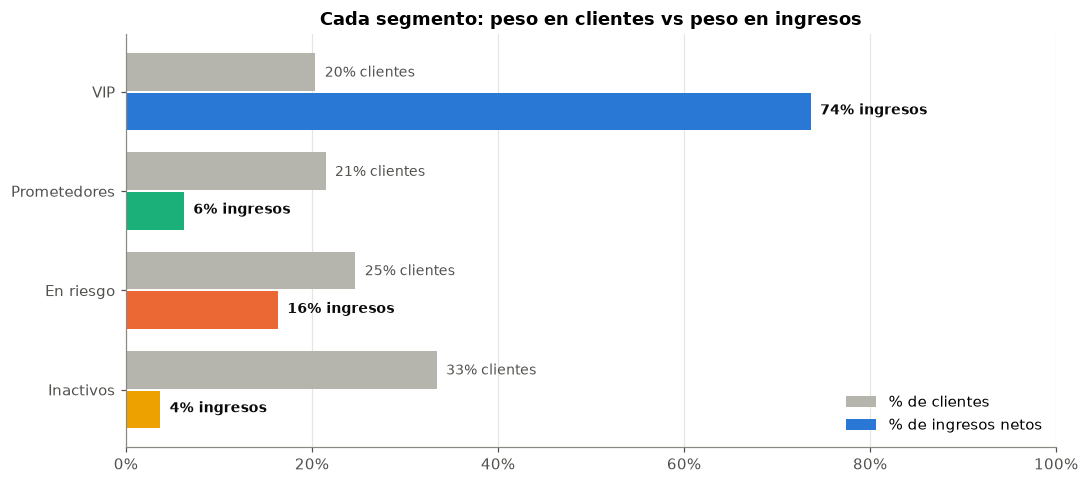

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(ORDEN_SEGMENTOS))
alto = 0.38
ax.barh(y - alto / 2 - 0.01, perfil["% clientes"], height=alto, color=GRIS, label="% de clientes")
ax.barh(y + alto / 2 + 0.01, perfil["% ingresos"], height=alto,
        color=[COLORES[s] for s in ORDEN_SEGMENTOS], label="% de ingresos netos")
for i, segmento in enumerate(ORDEN_SEGMENTOS):
    ax.text(perfil.loc[segmento, "% clientes"] + 1, i - alto / 2, f"{perfil.loc[segmento, '% clientes']:.0f}% clientes",
            va="center", fontsize=9, color="#52514e")
    ax.text(perfil.loc[segmento, "% ingresos"] + 1, i + alto / 2, f"{perfil.loc[segmento, '% ingresos']:.0f}% ingresos",
            va="center", fontsize=9, color="#0b0b0b", fontweight="bold")
ax.set_yticks(y, ORDEN_SEGMENTOS)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_title("Cada segmento: peso en clientes vs peso en ingresos")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

Este gráfico resume el negocio en una imagen: **los VIP son una minoría de los clientes pero generan la mayor parte de los ingresos**, mientras que los Inactivos son el grupo más numeroso y apenas aportan valor.

#### 7.3 Distribución de las variables RFM por segmento

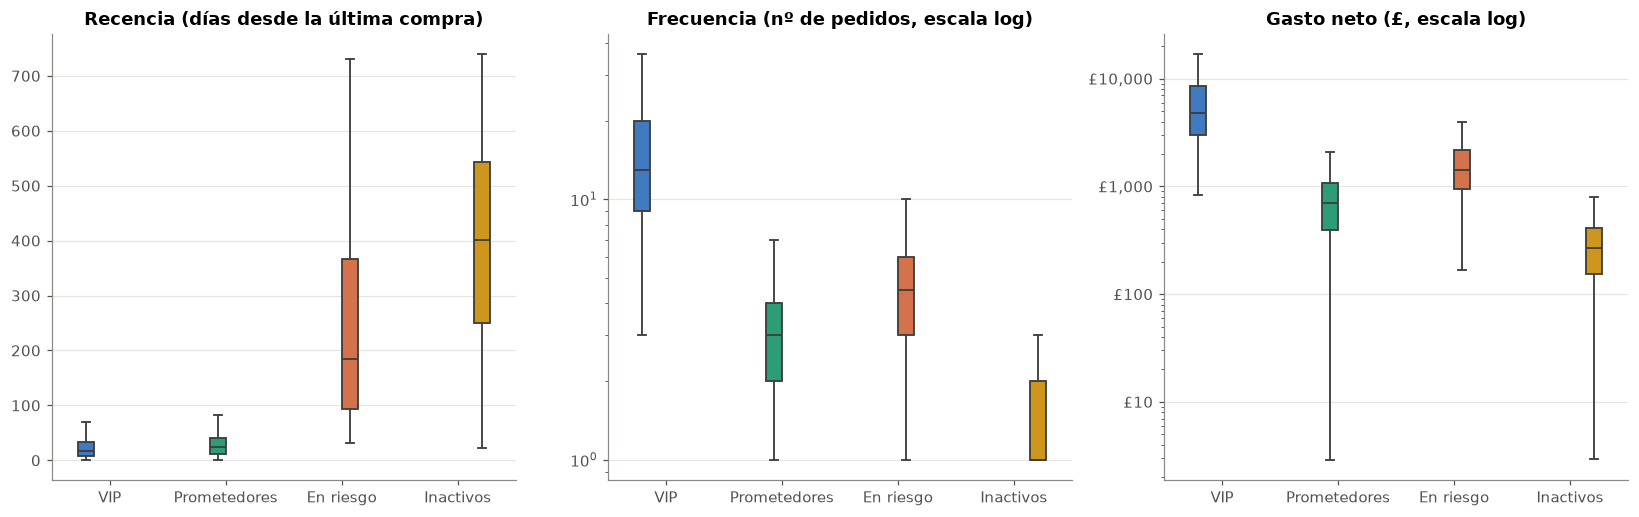

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
titulos = {"recencia": "Recencia (días desde la última compra)",
           "frecuencia": "Frecuencia (nº de pedidos, escala log)",
           "gasto": "Gasto neto (£, escala log)"}

for ax, variable in zip(axes, VARIABLES):
    sns.boxplot(data=features, x="segmento", y=variable, hue="segmento", palette=COLORES,
                order=ORDEN_SEGMENTOS, showfliers=False, width=0.55, linewidth=1.2, legend=False, ax=ax)
    if variable != "recencia":
        ax.set_yscale("log")
    ax.set_title(titulos[variable])
    ax.set_xlabel("")
    ax.set_ylabel("")
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
plt.tight_layout()
plt.show()

#### 7.4 Mapa de calor del perfil
Para ver de un vistazo en qué destaca cada segmento, comparamos la mediana de cada variable con la mediana global de todos los clientes. Un valor de **+100 %** significa que el segmento duplica al cliente típico; **-50 %**, que tiene la mitad.

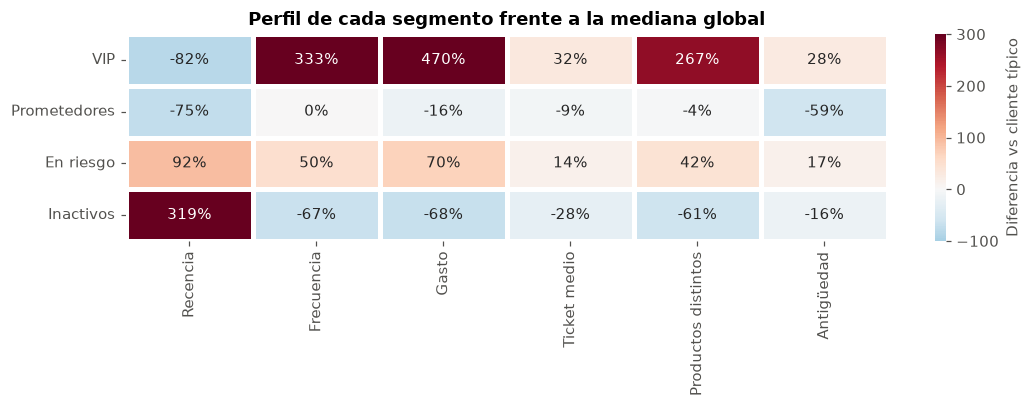

In [13]:
variables_perfil = {
    "recencia": "Recencia",
    "frecuencia": "Frecuencia",
    "gasto": "Gasto",
    "ticket_medio": "Ticket medio",
    "productos_distintos": "Productos distintos",
    "antiguedad_dias": "Antigüedad",
}
medianas = features.groupby("segmento", observed=True)[list(variables_perfil)].median()
relativo = (medianas / features[list(variables_perfil)].median() - 1) * 100
relativo = relativo.rename(columns=variables_perfil)

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(relativo.clip(-100, 300), annot=relativo.round(0).astype(int).astype(str) + "%", fmt="",
            cmap="RdBu_r", center=0, vmin=-100, vmax=300, linewidths=2, linecolor="white",
            cbar_kws={"label": "Diferencia vs cliente típico"}, ax=ax)
ax.set_title("Perfil de cada segmento frente a la mediana global")
ax.set_xlabel(""); ax.set_ylabel("")
ax.grid(False)
plt.tight_layout()
plt.show()

#### 7.5 Visualización de los segmentos
Representamos a cada cliente según su recencia y su gasto. Para no mezclar cuatro colores en el mismo gráfico (difíciles de distinguir con muchos puntos superpuestos), dibujamos **un panel por segmento**, resaltándolo sobre el resto de clientes en gris.

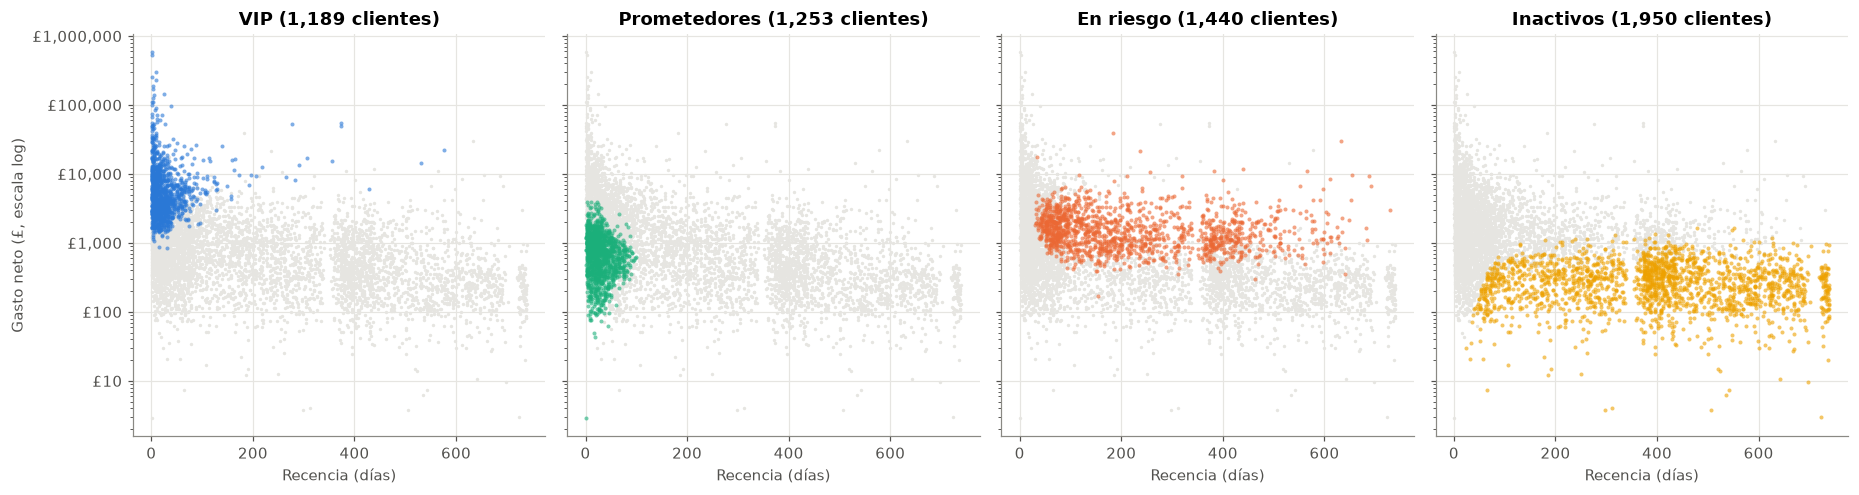

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharex=True, sharey=True)
for ax, segmento in zip(axes, ORDEN_SEGMENTOS):
    es_segmento = features["segmento"] == segmento
    ax.scatter(features.loc[~es_segmento, "recencia"], features.loc[~es_segmento, "gasto"],
               s=5, color="#e6e5e1", linewidths=0)
    ax.scatter(features.loc[es_segmento, "recencia"], features.loc[es_segmento, "gasto"],
               s=7, color=COLORES[segmento], alpha=0.6, linewidths=0)
    ax.set_title(f"{segmento} ({es_segmento.sum():,} clientes)")
    ax.set_yscale("log")
    ax.set_xlabel("Recencia (días)")
axes[0].set_ylabel("Gasto neto (£, escala log)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
plt.tight_layout()
plt.show()

Los segmentos ocupan zonas claramente distintas del espacio recencia-gasto:
- **VIP**: compraron recientemente y tienen el gasto más alto.
- **Prometedores**: también son recientes, pero con gasto todavía moderado.
- **En riesgo**: gasto medio-alto, pero llevan meses sin comprar.
- **Inactivos**: gasto bajo y mucho tiempo sin comprar.

#### 7.6 ¿Influye el país?

In [15]:
pais = features.groupby("segmento", observed=True).agg(
    pct_reino_unido=("es_reino_unido", "mean"),
    tasa_cancelacion_media=("tasa_cancelacion", "mean"),
)
pais["pct_reino_unido"] *= 100
pais["tasa_cancelacion_media"] *= 100
pais.round(1)

,pct_reino_unido,tasa_cancelacion_media
segmento,,
VIP,90.4,2.1
Prometedores,90.7,1.5
En riesgo,90.2,2.3
Inactivos,92.7,2.1


La proporción de clientes de Reino Unido es similar en todos los segmentos: **el comportamiento de compra no depende del país**, por lo que no es necesario segmentar por mercado. La tasa de cancelación media es baja en todos los grupos.

### 8. Descripción de los segmentos

| Segmento | Quiénes son | Riesgo de abandono | Valor |
|---|---|---|---|
| **VIP** | Compran a menudo, gastan mucho y han comprado recientemente. Muchos tienen perfil mayorista. | Bajo | Muy alto |
| **Prometedores** | Clientes recientes, con pocas compras y gasto todavía bajo. Muchos son clientes nuevos. | Medio | Potencial de crecimiento |
| **En riesgo** | Han sido buenos clientes (varias compras y gasto relevante) pero llevan meses sin comprar, más que su ciclo habitual de recompra. | **Alto** | Medio-alto |
| **Inactivos** | Compraron una o dos veces, con poco gasto, y hace más de un año. | Muy alto (probablemente ya perdidos) | Bajo |

### 9. De los segmentos a la acción

| Segmento | Objetivo | Acciones recomendadas |
|---|---|---|
| **VIP** | **Retener y fidelizar** | Programa de fidelidad, gestor de cuenta, acceso anticipado a novedades. **Evitar descuentos generalizados**: ya compran sin ellos y reducen el margen. |
| **Prometedores** | **Convertir en habituales** | Secuencia de *onboarding*, recomendaciones personalizadas según su primera compra, incentivo para el segundo/tercer pedido. |
| **En riesgo** | **Reactivar antes de perderlos** | Campaña de reactivación prioritaria (email personalizado, oferta limitada, encuesta de satisfacción). Es donde una acción tiene **mayor retorno**: valen mucho y aún se pueden recuperar. |
| **Inactivos** | **Recuperar a bajo coste** | Campañas automáticas y baratas (newsletter, ofertas de temporada, especialmente antes de Navidad). No invertir recursos caros. |

#### 9.1 Priorización: no todos los clientes en riesgo valen lo mismo
Como planteaba el esquema del proyecto (bloque D), dos clientes con el mismo riesgo no deben tratarse igual: hay que tener en cuenta su **valor económico**. Para construir la lista de clientes a contactar primero, dentro del segmento *En riesgo*:
- nos quedamos con los que llevan **más de 90 días sin comprar** (los que ya se han salido del ciclo de recompra habitual) y que han comprado **al menos 2 veces** (han demostrado que repiten, así que es más probable recuperarlos);
- y los ordenamos por **gasto neto**.

In [16]:
en_riesgo_df = features[features["segmento"] == "En riesgo"]
ingresos_en_juego = en_riesgo_df["gasto"].sum()

print(f"Clientes en riesgo: {len(en_riesgo_df):,}")
print(f"Ingresos históricos de estos clientes: £{ingresos_en_juego:,.0f} "
      f"({ingresos_en_juego / features['gasto'].sum():.1%} del total)")

candidatos = en_riesgo_df[(en_riesgo_df["recencia"] > 90) & (en_riesgo_df["frecuencia"] >= 2)]
print(f"Candidatos prioritarios (>90 días sin comprar y >=2 pedidos): {len(candidatos):,}")

prioridad = (candidatos.sort_values("gasto", ascending=False)
             [["pais", "recencia", "frecuencia", "gasto", "ticket_medio", "dias_entre_compras"]]
             .head(10).round(0))
prioridad

Clientes en riesgo: 1,440
Ingresos históricos de estos clientes: £2,678,152 (16.4% del total)
Candidatos prioritarios (>90 días sin comprar y >=2 pedidos): 1,065


,pais,recencia,frecuencia,gasto,ticket_medio,dias_entre_compras
customer_id,,,,,,
15098,United Kingdom,183,3,39620.0,13206.0,NaN
13902,Denmark,633,5,30375.0,6075.0,23.0
15749,United Kingdom,236,3,21536.0,7179.0,97.0
14134,United Kingdom,383,15,11123.0,742.0,35.0
15032,United Kingdom,257,8,10515.0,1314.0,79.0
12758,Portugal,117,7,9779.0,1397.0,104.0
14091,United Kingdom,655,2,9530.0,4765.0,44.0
14063,United Kingdom,687,7,9472.0,1353.0,8.0
14439,Greece,320,5,9443.0,1889.0,92.0


Estos clientes han gastado miles de libras y llevan meses sin comprar. **Recuperar solo a unos pocos de ellos compensa con creces el coste de una campaña personalizada.** Además, para los VIP conviene vigilar a los que empiezan a superar su ciclo habitual de recompra:

In [17]:
vip_df = features[features["segmento"] == "VIP"]
vip_enfriandose = vip_df[vip_df["recencia"] > 2 * vip_df["dias_entre_compras"]]

print(f"VIP que llevan más del doble de su tiempo habitual sin comprar: {len(vip_enfriandose):,} "
      f"({len(vip_enfriandose) / len(vip_df):.0%} de los VIP)")
print(f"Ingresos históricos de estos VIP: £{vip_enfriandose['gasto'].sum():,.0f}")

VIP que llevan más del doble de su tiempo habitual sin comprar: 62 (5% de los VIP)
Ingresos históricos de estos VIP: £822,517


Estos VIP "enfriándose" son una **alerta temprana**: todavía no están en el segmento En riesgo, pero su comportamiento ha cambiado. Son los candidatos perfectos para el modelo de predicción de churn de la siguiente fase.

### 10. Guardar resultados
Guardamos:
- La **asignación de segmento** de cada cliente (para que marketing pueda usarla en sus campañas).
- El **modelo entrenado** (preprocesado + K-Means en un único pipeline), para asignar segmento a nuevos clientes sin reentrenar.

In [18]:
features[["pais", "recencia", "frecuencia", "gasto", "ticket_medio", "segmento"]].to_csv(RUTA_SEGMENTOS)

modelo_segmentacion = make_pipeline(*[paso for _, paso in preprocesado.steps], kmeans)
joblib.dump({"modelo": modelo_segmentacion, "variables": VARIABLES, "nombres": NOMBRES},
            DIR_MODELOS / "segmentacion_kmeans.joblib")

print(f"Segmentos guardados en {RUTA_SEGMENTOS}")
print(f"Modelo guardado en {DIR_MODELOS / 'segmentacion_kmeans.joblib'}")

Segmentos guardados en ..\data\processed\segmentos_clientes.csv
Modelo guardado en ..\models\segmentacion_kmeans.joblib


Comprobamos que el modelo guardado funciona: lo cargamos y asignamos segmento a dos clientes ficticios.

In [19]:
cargado = joblib.load(DIR_MODELOS / "segmentacion_kmeans.joblib")

clientes_nuevos = pd.DataFrame({
    "recencia": [5, 300],
    "frecuencia": [40, 1],
    "gasto": [15_000, 120],
}, index=["Cliente A", "Cliente B"])

clusters = cargado["modelo"].predict(clientes_nuevos[cargado["variables"]])
clientes_nuevos["segmento_asignado"] = [cargado["nombres"][c] for c in clusters]
clientes_nuevos

,recencia,frecuencia,gasto,segmento_asignado
Cliente A,5,40,15000,VIP
Cliente B,300,1,120,Inactivos


### 11. Conclusiones

1. **Hemos identificado 4 segmentos de clientes** con K-Means sobre las variables RFM transformadas: **VIP, Prometedores, En riesgo e Inactivos**. El número de grupos se eligió combinando cuatro métricas (codo, silhouette, Davies-Bouldin y Calinski-Harabasz) con el criterio de que los segmentos fueran accionables.
2. **La segmentación es robusta:** prácticamente no cambia con distintas semillas (ARI ≈ 1,00) ni al entrenar con distintas submuestras de clientes (ARI ≈ 0,98), y añadir más variables empeora la separación de los grupos.
3. **El valor está muy concentrado:** los VIP son el **20 % de los clientes pero generan el 74 % de los ingresos**. Retenerlos es la prioridad número uno, y ya hemos detectado 62 VIP que empiezan a enfriarse (más de 820.000 £ de gasto histórico).
4. **El segmento En riesgo es la mayor oportunidad:** 1.440 clientes (25 %) que han generado el 16 % de los ingresos y que todavía se pueden recuperar. Hemos generado una **lista priorizada por valor económico** para la campaña de reactivación.
5. El resultado es **utilizable por negocio**: un CSV con el segmento de cada cliente y un modelo guardado capaz de segmentar a clientes nuevos.

**Limitaciones**
- K-Means asume grupos aproximadamente "esféricos" y los clientes forman un continuo, por lo que los clientes en la frontera entre dos segmentos podrían pertenecer a cualquiera de ellos.
- El análisis es una **foto fija** a fecha de diciembre de 2011. En un entorno real la segmentación se recalcularía periódicamente (por ejemplo, cada mes).
- Solo incluye clientes registrados (~77 % de las transacciones originales).

**Próximos pasos**
- **Modelo de predicción de churn** (bloque C del esquema): definir una ventana de observación y otra de predicción, y entrenar un modelo supervisado que estime la **probabilidad de abandono** de cada cliente. El segmento obtenido aquí se puede usar como variable del modelo.
- **Customer Lifetime Value (CLV)**: estimar el valor futuro de cada cliente para combinarlo con la probabilidad de churn y priorizar las acciones de retención (riesgo × valor).